<a href="https://colab.research.google.com/github/tso-eng/Machine-Learning-Sciktlearn/blob/Engenharia-de-Processo---Etanol-de-Milho/Linear_Regression_S%C3%B3lidosvsEtanol.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#Definição das Bibliotecas

import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score
import matplotlib.pyplot as plt
import pandas as pd

In [ ]:
# Linha para Gerar solidos e etanol randômico para testar o modelo

#rng = np.random.default_rng(42)
#solidos = rng.uniform(32,38,size = 100)
#ruido = rng.normal(0,0.25, size = 100)
#etanol = 3 + 0.35*solidos + ruido

# Dados vindo da base de dados de Fermentação de CDC

df1 = pd.read_excel("Fermentacao.xlsx")

# Remove valores nulos iniciais
df_limpo = df1[['Solidos', 'Etanol GL']].dropna()

# --- Tratamento de Outliers usando o método IQR ---
# Para Sólidos
Q1_S = df_limpo['Solidos'].quantile(0.25)
Q3_S = df_limpo['Solidos'].quantile(0.75)
IQR_S = Q3_S - Q1_S
limite_inferior_S = Q1_S - 1.5 * IQR_S
limite_superior_S = Q3_S + 1.5 * IQR_S

# Para Etanol
Q1_E = df_limpo['Etanol GL'].quantile(0.25)
Q3_E = df_limpo['Etanol GL'].quantile(0.75)
IQR_E = Q3_E - Q1_E
limite_inferior_E = Q1_E - 1.5 * IQR_E
limite_superior_E = Q3_E + 1.5 * IQR_E

# Filtrando o DataFrame para remover os outliers
df_sem_outliers = df_limpo[
    (df_limpo['Solidos'] >= limite_inferior_S) & (df_limpo['Solidos'] <= limite_superior_S) &
    (df_limpo['Etanol GL'] >= limite_inferior_E) & (df_limpo['Etanol GL'] <= limite_superior_E)
]

print(f"Linhas antes do tratamento: {len(df_limpo)}")
print(f"Linhas após remoção de outliers: {len(df_sem_outliers)}")

# Seleção de variáveis com dados tratados
X = df_sem_outliers[['Solidos']]
Y = df_sem_outliers['Etanol GL']

X_treino, X_teste, Y_treino, Y_teste = train_test_split(X, Y, test_size = 0.20, random_state = 42)

modelo = LinearRegression()
modelo.fit(X_treino, Y_treino)
Y_previsto = modelo.predict(X_teste)

mae = mean_absolute_error(Y_teste, Y_previsto)
r2 = r2_score(Y_teste, Y_previsto)

print("\n--- Métricas do Novo Modelo ---")
print("MAE:", mae)
print("R2:", r2)
print("Coeficiente angular:", modelo.coef_[0])
print("Coeficiente linear:", modelo.intercept_)


Linhas antes do tratamento: 273
Linhas após remoção de outliers: 265

--- Métricas do Novo Modelo ---
MAE: 0.3381784398344346
R2: 0.2758671315208209
Coeficiente angular: 0.21492264068976547
Coeficiente linear: 11.25890910126255


In [ ]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# 1. Padronizar os dados para que o KMeans funcione corretamente
scaler = StandardScaler()
dados_escala = scaler.fit_transform(df_sem_outliers[['Solidos', 'Etanol GL']])

# 2. Aplicar o algoritmo KMeans (definindo 3 clusters como exemplo)
n_clusters = 3
kmeans = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)
df_sem_outliers['Cluster'] = kmeans.fit_predict(dados_escala)

print("Quantidade de pontos por cluster:")
print(df_sem_outliers['Cluster'].value_counts())

Quantidade de pontos por cluster:
Cluster
2    102
0     93
1     70
Name: count, dtype: int64


/tmp/ipykernel_899/1989469696.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_sem_outliers['Cluster'] = kmeans.fit_predict(dados_escala)



--- Métricas Cluster 0 (Cor: blue) ---
R2: 0.0567 | MAE: 0.1637
Equação: y = 0.1148 * x + 14.3070

--- Métricas Cluster 1 (Cor: green) ---
R2: 0.0205 | MAE: 0.1894
Equação: y = -0.0165 * x + 19.6685

--- Métricas Cluster 2 (Cor: orange) ---
R2: -0.1255 | MAE: 0.3531
Equação: y = -0.0470 * x + 19.7257


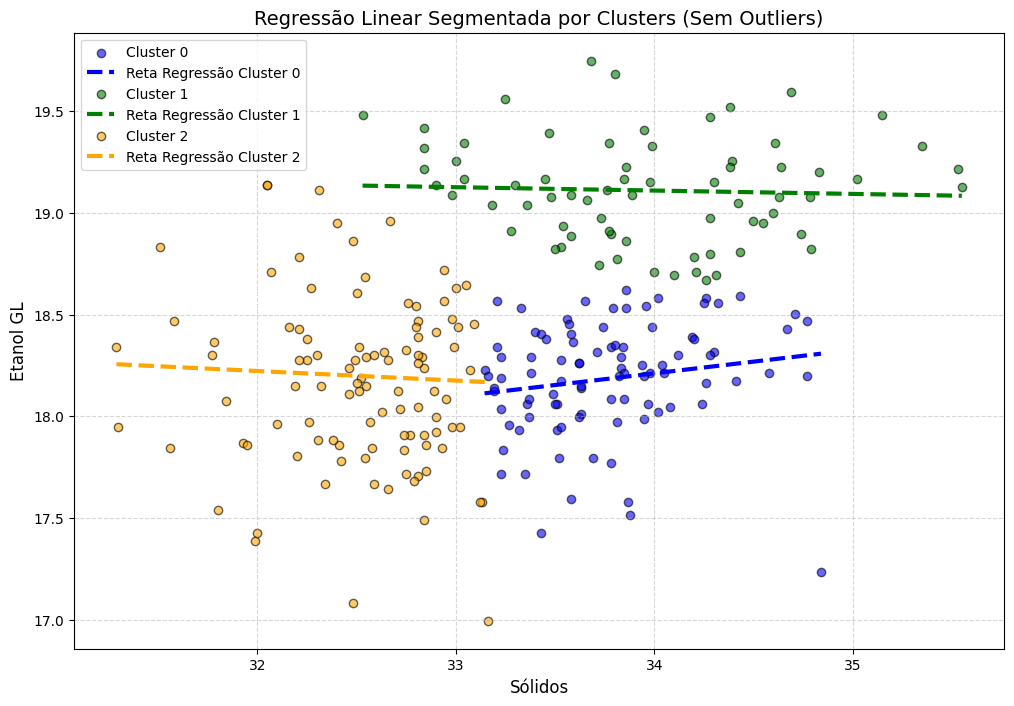

In [ ]:
# 3. Treinar uma regressão linear para cada cluster e plotar os resultados
plt.figure(figsize=(12, 8))

# Definir cores para identificar cada cluster
cores = ['blue', 'green', 'orange']

for cluster_id in range(n_clusters):
    # Filtrar dados do cluster atual
    df_cluster = df_sem_outliers[df_sem_outliers['Cluster'] == cluster_id]

    X_c = df_cluster[['Solidos']]
    Y_c = df_cluster['Etanol GL']

    # Dividir em treino e teste dentro do cluster
    X_tr, X_te, Y_tr, Y_te = train_test_split(X_c, Y_c, test_size=0.20, random_state=42)

    # Treinar o modelo linear para o cluster específico
    modelo_c = LinearRegression()
    modelo_c.fit(X_tr, Y_tr)
    Y_prev = modelo_c.predict(X_te)

    # Métricas de avaliação por cluster
    r2_c = r2_score(Y_te, Y_prev)
    mae_c = mean_absolute_error(Y_te, Y_prev)
    print(f"\n--- Métricas Cluster {cluster_id} (Cor: {cores[cluster_id]}) ---")
    print(f"R2: {r2_c:.4f} | MAE: {mae_c:.4f}")
    print(f"Equação: y = {modelo_c.coef_[0]:.4f} * x + {modelo_c.intercept_:.4f}")

    # Plotar os pontos reais deste cluster (usando todos os pontos do cluster para melhor visualização)
    plt.scatter(df_cluster['Solidos'], df_cluster['Etanol GL'], color=cores[cluster_id], label=f'Cluster {cluster_id}', alpha=0.6, edgecolors='k')

    # Plotar a reta de regressão ajustada para este cluster
    x_reta = np.linspace(df_cluster['Solidos'].min(), df_cluster['Solidos'].max(), 100).reshape(-1, 1)
    y_reta = modelo_c.predict(pd.DataFrame(x_reta, columns=['Solidos']))
    plt.plot(x_reta, y_reta, color=cores[cluster_id], linestyle='--', linewidth=3, label=f'Reta Regressão Cluster {cluster_id}')

plt.title('Regressão Linear Segmentada por Clusters (Sem Outliers)', fontsize=14)
plt.xlabel('Sólidos', fontsize=12)
plt.ylabel('Etanol GL', fontsize=12)
plt.legend(fontsize=10)
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [ ]:
# Filtrando os dados pertencentes apenas ao Cluster 1
df_cluster_1 = df_sem_outliers[df_sem_outliers['Cluster'] == 1]

# Exibindo um resumo da quantidade de linhas e as primeiras linhas da tabela
print(f"Total de registros no Cluster 1: {len(df_cluster_1)} linhas\n")
display(df_cluster_1)

Total de registros no Cluster 1: 70 linhas



,Solidos,Etanol GL,Cluster
7,32.84,19.214195,1
91,34.20,18.783270,1
109,33.53,18.833967,1
110,34.28,18.795944,1
126,34.00,18.707224,1
...,...,...,...
303,33.66,19.062104,1
304,33.77,18.910013,1
311,34.79,18.821293,1
312,34.55,18.948035,1


In [ ]:
# 1. Identificar as colunas disponíveis no arquivo original
print("Colunas disponíveis no arquivo original:")
print(df1.columns.tolist())

# 2. Recuperar as informações das bateladas originais do Cluster 1
# Usamos o índice do df_cluster_1 para filtrar as linhas correspondentes no df1 original
bateladas_cluster_1 = df1.loc[df_cluster_1.index].copy()

# Identificar colunas que parecem conter informações de Data ou Hora (corrigindo a variável de 'palabra' para 'palavra')
colunas_tempo = [col for col in df1.columns if any(palavra in col.lower() for palavra in ['data', 'hora', 'tempo', 'date', 'time', 'cheio', 'encheu'])]

# Selecionar as colunas de interesse: Batelada, Sólidos, Etanol GL e as colunas de tempo encontradas
colunas_fim = ['Batelada', 'Solidos', 'Etanol GL'] + colunas_tempo
colunas_existentes = [col for col in colunas_fim if col in bateladas_cluster_1.columns]

# Exibir a tabela do Cluster 1 com as informações de tempo
print(f"\nTabela do Cluster 1 com colunas de identificação e tempo:")
display(bateladas_cluster_1[colunas_existentes])

Colunas disponíveis no arquivo original:
['Batelada', 'Solidos', 'Brix', 'Brix/Solidos', 'pH', 'Etanol GL', 'Glicerol', 'Ácido Lát', 'Ácido Ac', 'Etanol/Sólidos (%)', 'Etanol/Brix ']

Tabela do Cluster 1 com colunas de identificação e tempo:


,Batelada,Solidos,Etanol GL
7,3993,32.84,19.214195
91,4077,34.20,18.783270
109,4095,33.53,18.833967
110,4096,34.28,18.795944
126,4112,34.00,18.707224
...,...,...,...
303,4289,33.66,19.062104
304,4290,33.77,18.910013
311,4297,34.79,18.821293
312,4298,34.55,18.948035


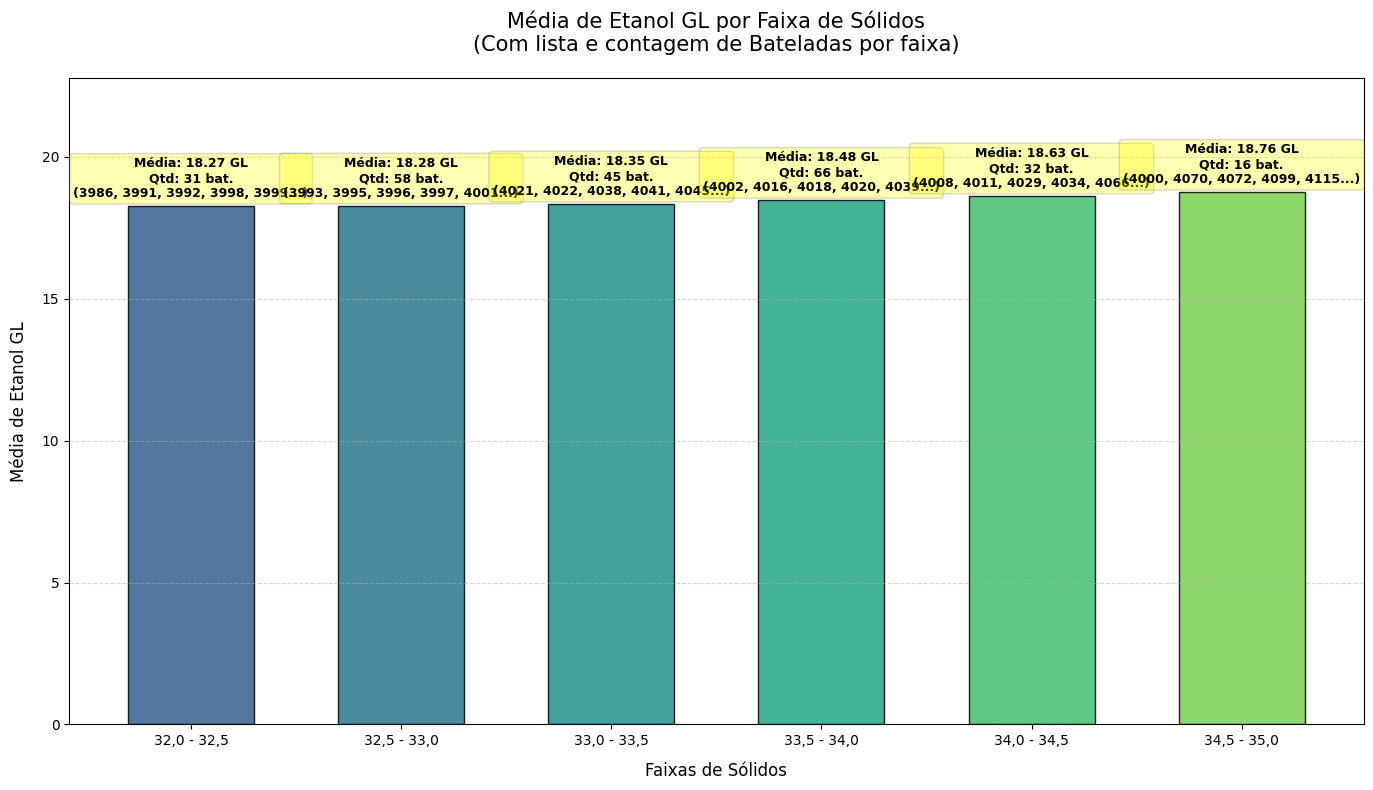

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Obter o dataframe original com o número das bateladas para os dados sem outliers
df_analise = df1.loc[df_sem_outliers.index].copy()

# 2. Definir os limites e rótulos para as faixas de sólidos
limites = [32.0, 32.5, 33.0, 33.5, 34.0, 34.5, 35.0]
rotulos = ['32,0 - 32,5', '32,5 - 33,0', '33,0 - 33,5', '33,5 - 34,0', '34,0 - 34,5', '34,5 - 35,0']

# Criar a coluna de faixas de Sólidos
df_analise['Faixa_Solidos'] = pd.cut(df_analise['Solidos'], bins=limites, labels=rotulos, include_lowest=True)

# Remover possíveis registros que fiquem fora dessas faixas específicas
df_filtrado = df_analise.dropna(subset=['Faixa_Solidos'])

# 3. Agrupar os dados por faixa
grupos = df_filtrado.groupby('Faixa_Solidos', observed=False)

faixas_plot = []
medias_gl = []
contagem_bateladas = []
lista_bateladas = []

for nome_grupo, df_grupo in grupos:
    faixas_plot.append(nome_grupo)
    medias_gl.append(df_grupo['Etanol GL'].mean())
    contagem_bateladas.append(len(df_grupo))
    # Guardar a lista das bateladas associadas a este grupo
    lista_b = df_grupo['Batelada'].dropna().astype(int).unique().tolist()
    lista_bateladas.append(lista_b)

# 4. Construção do gráfico de barras
plt.figure(figsize=(14, 8))
cores_barras = plt.cm.viridis(np.linspace(0.3, 0.8, len(rotulos)))

barras = plt.bar(faixas_plot, medias_gl, color=cores_barras, edgecolor='black', alpha=0.85, width=0.6)

# Adicionar o número de bateladas e as bateladas em cima de cada barra
for barra, media, qtd, bateladas in zip(barras, medias_gl, contagem_bateladas, lista_bateladas):
    # Limitar o texto de bateladas se houverem muitas para não estourar o layout
    texto_bateladas = ", ".join(map(str, bateladas[:5]))
    if len(bateladas) > 5:
        texto_bateladas += "..."

    label_texto = f"Média: {media:.2f} GL\nQtd: {qtd} bat.\n({texto_bateladas})"

    plt.text(
        barra.get_x() + barra.get_width()/2.0,
        media + 0.2,
        label_texto,
        ha='center',
        va='bottom',
        fontsize=9,
        fontweight='bold',
        bbox=dict(boxstyle="round,pad=0.3", fc="yellow", alpha=0.3, ec="gray")
    )

# Customizações estéticas
plt.title('Média de Etanol GL por Faixa de Sólidos\n(Com lista e contagem de Bateladas por faixa)', fontsize=15, pad=20)
plt.xlabel('Faixas de Sólidos', fontsize=12, labelpad=10)
plt.ylabel('Média de Etanol GL', fontsize=12, labelpad=10)
plt.ylim(0, max(medias_gl) + 4) # Margem superior para acomodar os textos de detalhe
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

/tmp/ipykernel_899/3726286912.py:49: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cores_barras = plt.cm.get_cmap(mapa_cor)(np.linspace(0.3, 0.8, len(rotulos)))


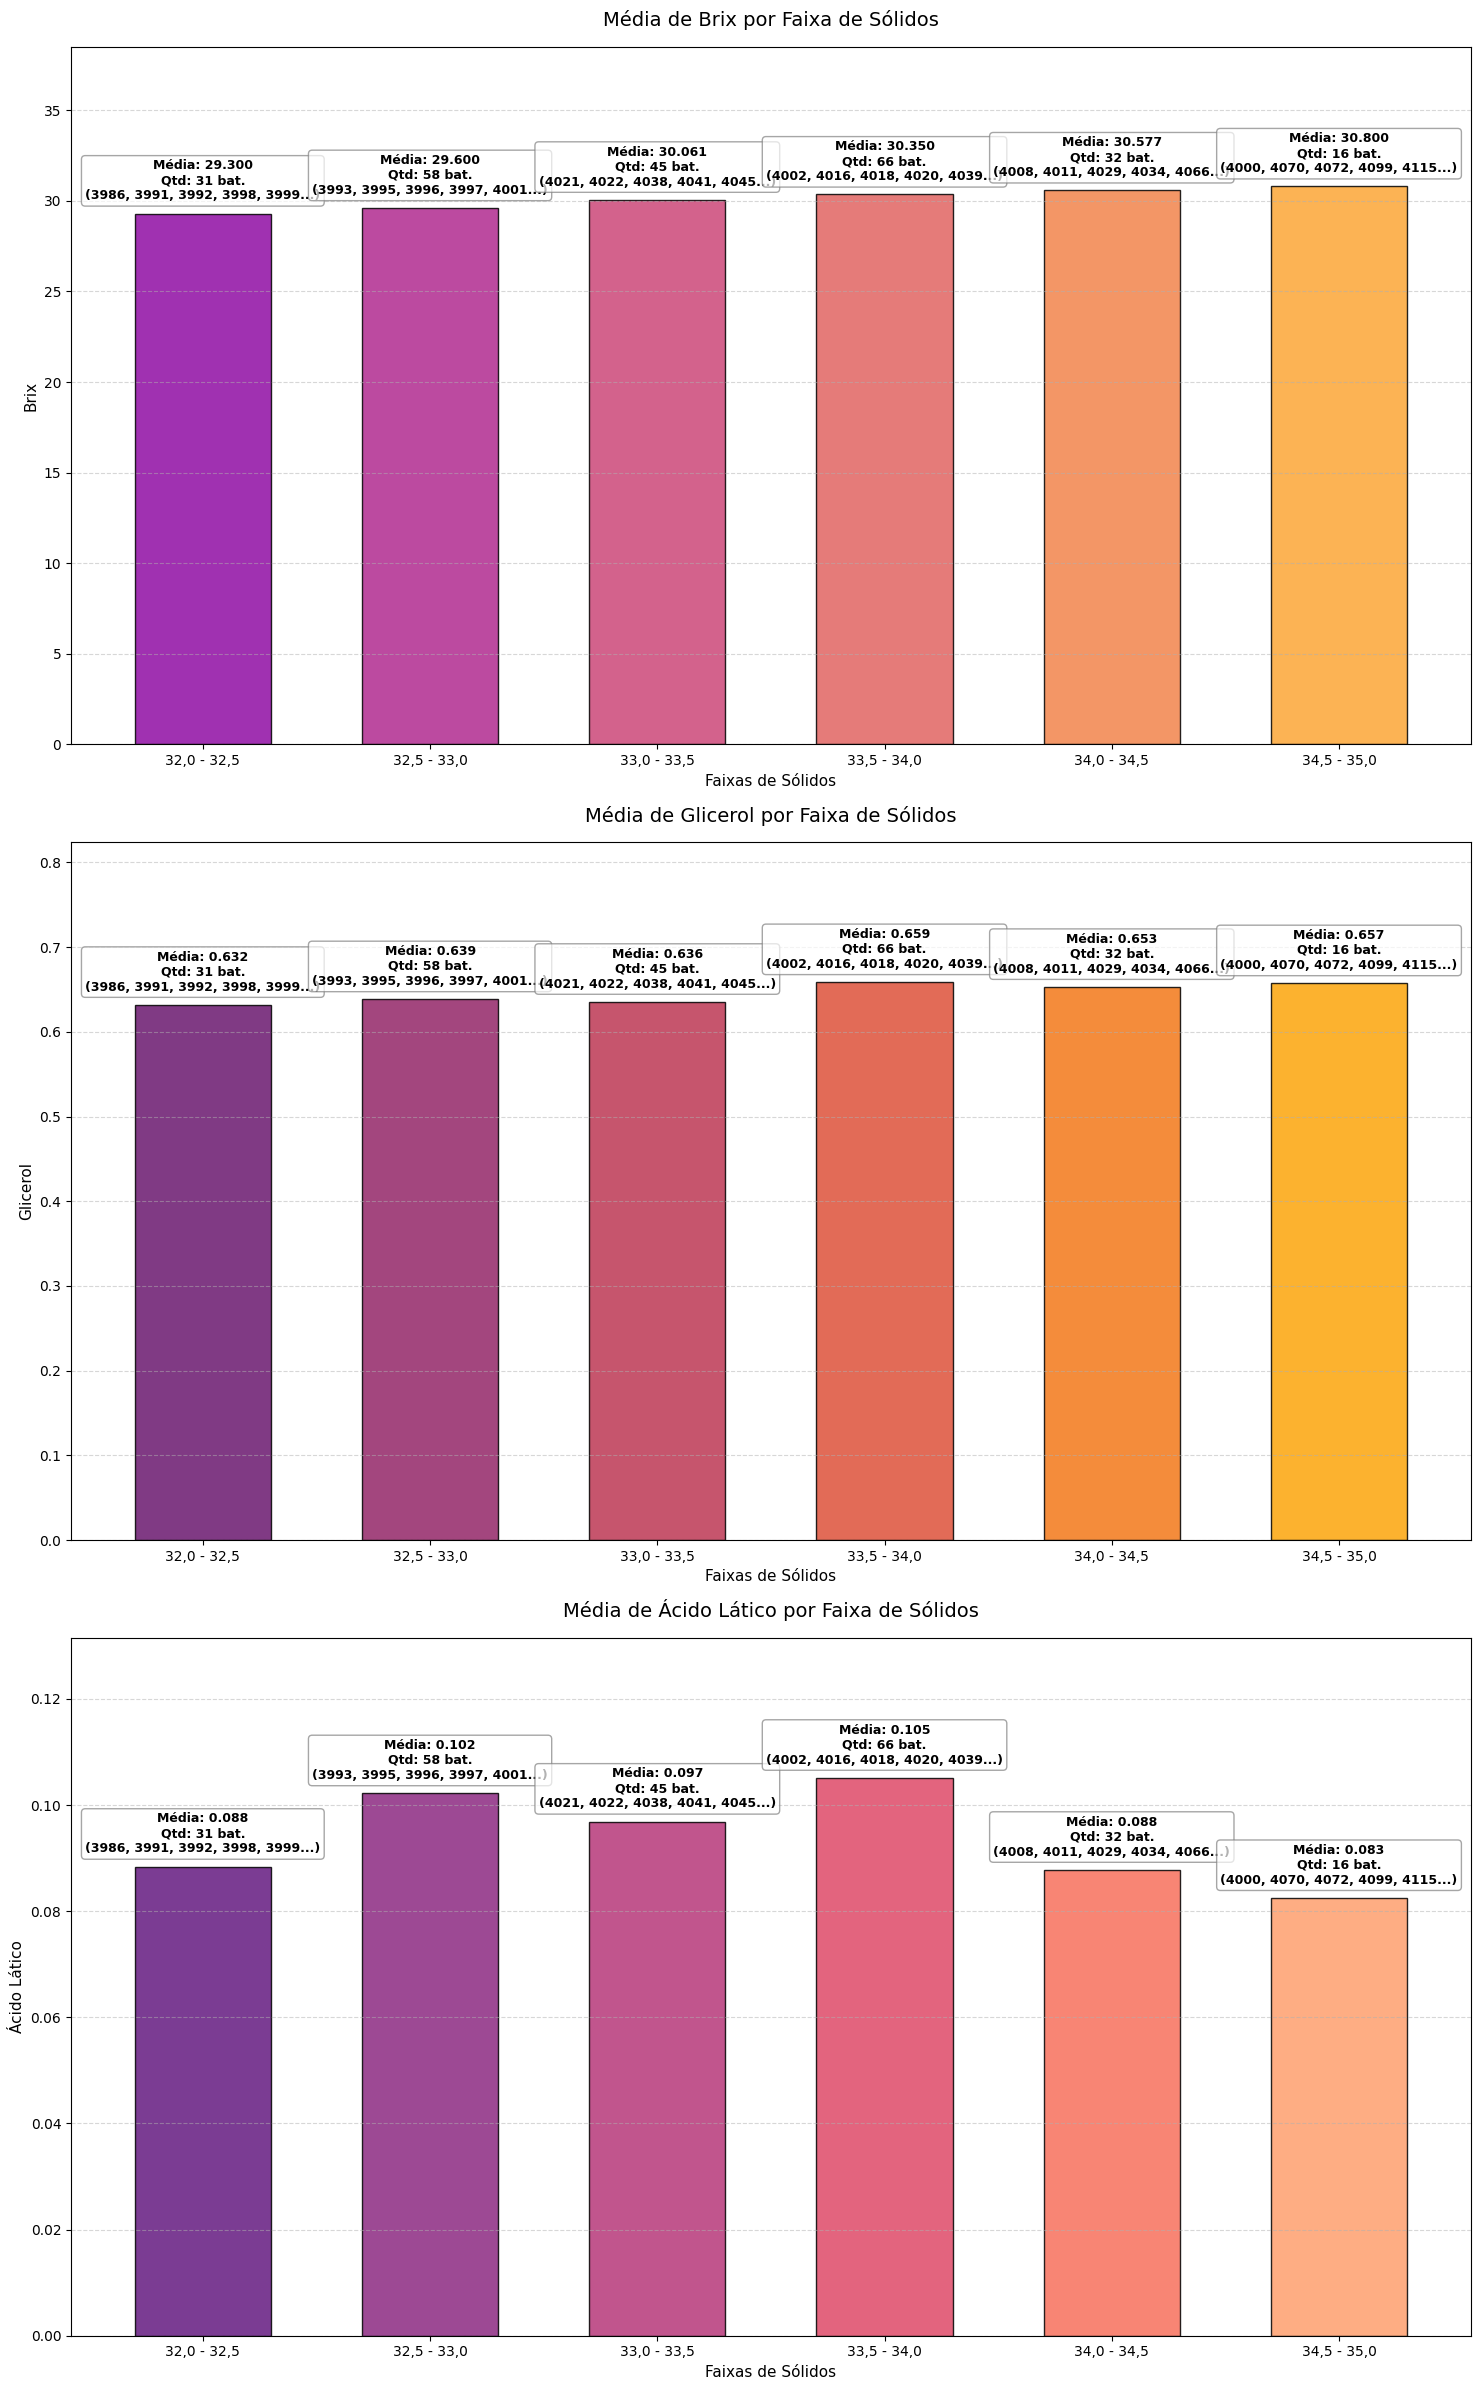

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Recuperar o DataFrame sem outliers e trazer as colunas originais necessárias
colunas_interesse = ['Batelada', 'Solidos', 'Brix', 'Glicerol', 'Ácido Lát']
df_multi = df1.loc[df_sem_outliers.index, colunas_interesse].copy()

# 2. Criar as faixas de Sólidos utilizando os mesmos limites anteriores
limites = [32.0, 32.5, 33.0, 33.5, 34.0, 34.5, 35.0]
rotulos = ['32,0 - 32,5', '32,5 - 33,0', '33,0 - 33,5', '33,5 - 34,0', '34,0 - 34,5', '34,5 - 35,0']
df_multi['Faixa_Solidos'] = pd.cut(df_multi['Solidos'], bins=limites, labels=rotulos, include_lowest=True)

# Remover possíveis nulos nas faixas
df_multi_filtrado = df_multi.dropna(subset=['Faixa_Solidos'])

# 3. Agrupar os dados
grupos_m = df_multi_filtrado.groupby('Faixa_Solidos', observed=False)

faixas_plot = []
medias_brix = []
medias_glicerol = []
medias_latico = []
contagem_bateladas = []
lista_bateladas = []

for nome_grupo, df_grupo in grupos_m:
    faixas_plot.append(nome_grupo)
    medias_brix.append(df_grupo['Brix'].mean())
    medias_glicerol.append(df_grupo['Glicerol'].mean())
    medias_latico.append(df_grupo['Ácido Lát'].mean())
    contagem_bateladas.append(len(df_grupo))

    # Obter lista de bateladas exclusivas
    lista_b = df_grupo['Batelada'].dropna().astype(int).unique().tolist()
    lista_bateladas.append(lista_b)

# 4. Configurar e plotar os 3 gráficos em subplots (um abaixo do outro)
fig, eixos = plt.subplots(3, 1, figsize=(15, 24))

variaveis = [
    ('Brix', medias_brix, 'plasma', 'Média de Brix'),
    ('Glicerol', medias_glicerol, 'inferno', 'Média de Glicerol'),
    ('Ácido Lático', medias_latico, 'magma', 'Média de Ácido Lático')
]

for i, (nome_var, valores_var, mapa_cor, titulo_grafico) in enumerate(variaveis):
    ax = eixos[i]
    cores_barras = plt.cm.get_cmap(mapa_cor)(np.linspace(0.3, 0.8, len(rotulos)))
    barras = ax.bar(faixas_plot, valores_var, color=cores_barras, edgecolor='black', alpha=0.85, width=0.6)

    # Adicionar rótulos informativos sobre cada barra
    for barra, valor, qtd, bateladas in zip(barras, valores_var, contagem_bateladas, lista_bateladas):
        # Se o valor for NaN (caso não tenha dados na faixa), pula
        if np.isnan(valor):
            continue

        texto_bat = ", ".join(map(str, bateladas[:5]))
        if len(bateladas) > 5:
            texto_bat += "..."

        label_texto = f"Média: {valor:.3f}\nQtd: {qtd} bat.\n({texto_bat})"

        ax.text(
            barra.get_x() + barra.get_width()/2.0,
            valor + (max(valores_var) * 0.02), # deslocamento proporcional ao topo da barra
            label_texto,
            ha='center',
            va='bottom',
            fontsize=9,
            fontweight='bold',
            bbox=dict(boxstyle="round,pad=0.3", fc="white", alpha=0.7, ec="gray")
        )

    ax.set_title(f'{titulo_grafico} por Faixa de Sólidos', fontsize=14, pad=15)
    ax.set_xlabel('Faixas de Sólidos', fontsize=11)
    ax.set_ylabel(nome_var, fontsize=11)
    ax.set_ylim(0, max(valores_var) * 1.25) # espaço extra no topo para o texto informativo
    ax.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

In [ ]:
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, r2_score
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Preparar os dados para a rede neural a partir do df1 (removendo as colunas solicitadas)
# Mantemos apenas as colunas independentes de processo sugeridas
colunas_preditoras = ['Solidos', 'pH', 'Glicerol', 'Ácido Lát', 'Ácido Ac']

# Garantimos que os dados estejam limpos de nulos
df_nn = df1[['Etanol GL'] + colunas_preditoras].dropna()

# Aplicando o filtro de outliers que usamos antes para manter a consistência
df_nn_limpo = df_nn[
    (df_nn['Solidos'] >= limite_inferior_S) & (df_nn['Solidos'] <= limite_superior_S) &
    (df_nn['Etanol GL'] >= limite_inferior_E) & (df_nn['Etanol GL'] <= limite_superior_E)
]

X_nn = df_nn_limpo[colunas_preditoras]
Y_nn = df_nn_limpo['Etanol GL']

# 2. Divisão Treino e Teste
X_train_nn, X_test_nn, Y_train_nn, Y_test_nn = train_test_split(X_nn, Y_nn, test_size=0.20, random_state=42)

# 3. Padronização das features
scaler_X = StandardScaler()
X_train_scaled = scaler_X.fit_transform(X_train_nn)
X_test_scaled = scaler_X.transform(X_test_nn)

# 4. Treinar a Rede Neural (MLPRegressor)
mlp = MLPRegressor(hidden_layer_sizes=(100, 50), activation='relu', solver='adam', max_iter=1000, random_state=42)
mlp.fit(X_train_scaled, Y_train_nn)

# Predições e avaliação
Y_pred_nn = mlp.predict(X_test_scaled)
print("--- Métricas da Rede Neural (Atualizada) ---")
print(f"MAE: {mean_absolute_error(Y_test_nn, Y_pred_nn):.4f}")
print(f"R2 Score: {r2_score(Y_test_nn, Y_pred_nn):.4f}")

--- Métricas da Rede Neural (Atualizada) ---
MAE: 0.6707
R2 Score: -12.6088



--- Melhor Combinação de Variáveis para Maximizar o Etanol GL (Previsão da Rede Neural Atualizada) ---
Previsão Máxima de Etanol GL: 18.7998 GL



,286
Solidos,35.53
pH,4.66
Glicerol,0.77
Ácido Lát,0.10
Ácido Ac,0.11


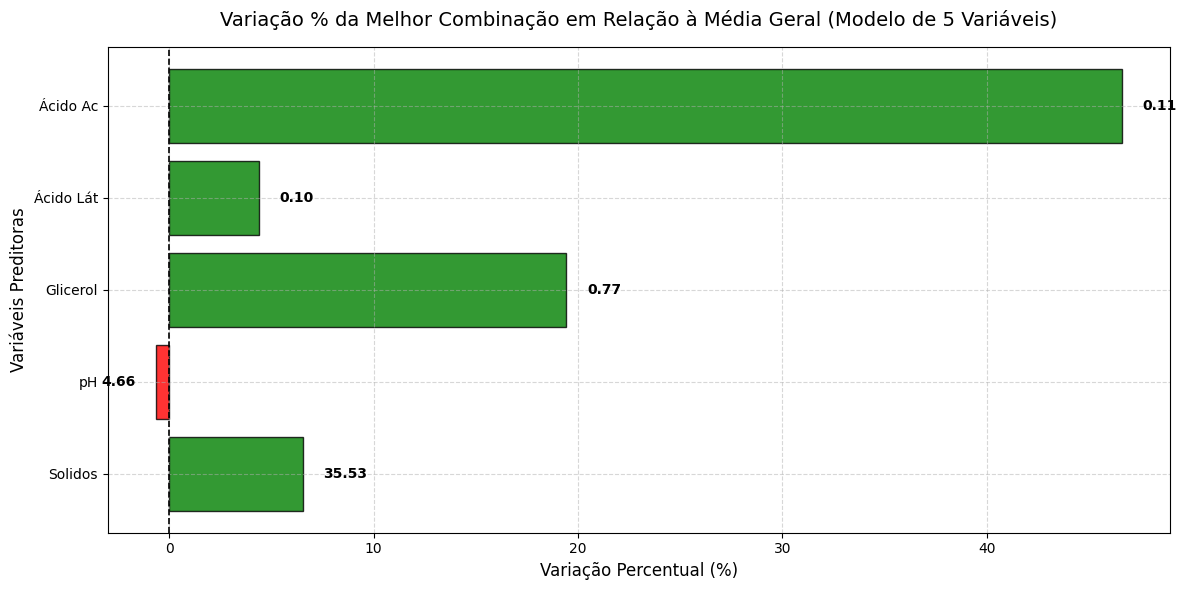

In [ ]:
# 5. Encontrar a melhor combinação de variáveis para maximizar o Etanol GL com o modelo novo
todas_predicoes = mlp.predict(scaler_X.transform(X_nn))
melhor_indice = np.argmax(todas_predicoes)

melhor_predicao = todas_predicoes[melhor_indice]
melhores_features = X_nn.iloc[melhor_indice]

# Exibir a melhor combinação encontrada
print("\n--- Melhor Combinação de Variáveis para Maximizar o Etanol GL (Previsão da Rede Neural Atualizada) ---")
print(f"Previsão Máxima de Etanol GL: {melhor_predicao:.4f} GL\n")

df_melhor = pd.DataFrame(melhores_features).rename(columns={melhor_indice: 'Valor Ideal'})
display(df_melhor)

# 6. Plotar a variação percentual em relação às médias do processo real
medias_gerais = X_nn.mean()

plt.figure(figsize=(12, 6))
variacao_percentual = ((melhores_features - medias_gerais) / medias_gerais) * 100

cores_plot = ['green' if val >= 0 else 'red' for val in variacao_percentual]

plt.barh(variacao_percentual.index, variacao_percentual.values, color=cores_plot, edgecolor='black', alpha=0.8)
plt.axvline(0, color='black', linestyle='--', linewidth=1.2)

plt.title('Variação % da Melhor Combinação em Relação à Média Geral (Modelo de 5 Variáveis)', fontsize=14, pad=15)
plt.xlabel('Variação Percentual (%)', fontsize=12)
plt.ylabel('Variáveis Preditoras', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)

# Adicionando os valores absolutos ideais nas pontas das barras
for index, value in enumerate(variacao_percentual.values):
    valor_real = melhores_features.values[index]
    alinhamento = 'left' if value >= 0 else 'right'
    deslocamento = 1 if value >= 0 else -1
    plt.text(value + deslocamento, index, f"{valor_real:.2f}", va='center', ha=alinhamento, fontweight='bold', fontsize=10)

plt.tight_layout()
plt.show()

In [ ]:
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, r2_score
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Preparar os dados para a rede neural a partir do df1 (removendo outliers com base nas variáveis principais)
# Vamos selecionar as colunas numéricas preditoras disponíveis
colunas_preditoras = ['Solidos', 'Brix', 'Brix/Solidos', 'pH', 'Glicerol', 'Ácido Lát', 'Ácido Ac', 'Etanol/Sólidos (%)', 'Etanol/Brix ']

# Garantimos que os dados estejam limpos de nulos
df_nn = df1[['Etanol GL'] + colunas_preditoras].dropna()

# Aplicando o filtro de outliers que usamos antes para manter a consistência
df_nn_limpo = df_nn[
    (df_nn['Solidos'] >= limite_inferior_S) & (df_nn['Solidos'] <= limite_superior_S) &
    (df_nn['Etanol GL'] >= limite_inferior_E) & (df_nn['Etanol GL'] <= limite_superior_E)
]

X_nn = df_nn_limpo[colunas_preditoras]
Y_nn = df_nn_limpo['Etanol GL']

# 2. Divisão Treino e Teste
X_train_nn, X_test_nn, Y_train_nn, Y_test_nn = train_test_split(X_nn, Y_nn, test_size=0.20, random_state=42)

# 3. Padronização das features (essencial para Redes Neurais)
scaler_X = StandardScaler()
X_train_scaled = scaler_X.fit_transform(X_train_nn)
X_test_scaled = scaler_X.transform(X_test_nn)

# 4. Treinar a Rede Neural (MLPRegressor)
mlp = MLPRegressor(hidden_layer_sizes=(100, 50), activation='relu', solver='adam', max_iter=1000, random_state=42)
mlp.fit(X_train_scaled, Y_train_nn)

# Predições e avaliação
Y_pred_nn = mlp.predict(X_test_scaled)
print(f"--- Métricas da Rede Neural ---")
print(f"MAE: {mean_absolute_error(Y_test_nn, Y_pred_nn):.4f}")
print(f"R2 Score: {r2_score(Y_test_nn, Y_pred_nn):.4f}")

--- Métricas da Rede Neural ---
MAE: 0.6391
R2 Score: -15.5022



--- Melhor Combinação de Variáveis para Maximizar o Etanol GL (Previsão da Rede Neural) ---
Previsão Máxima de Etanol GL: 33.2277 GL



,24
Solidos,32.410000
Brix,29.690000
Brix/Solidos,0.916075
pH,4.810000
Glicerol,0.060000
Ácido Lát,0.060000
Ácido Ac,0.070000
Etanol/Sólidos (%),0.434742
Etanol/Brix,0.474571


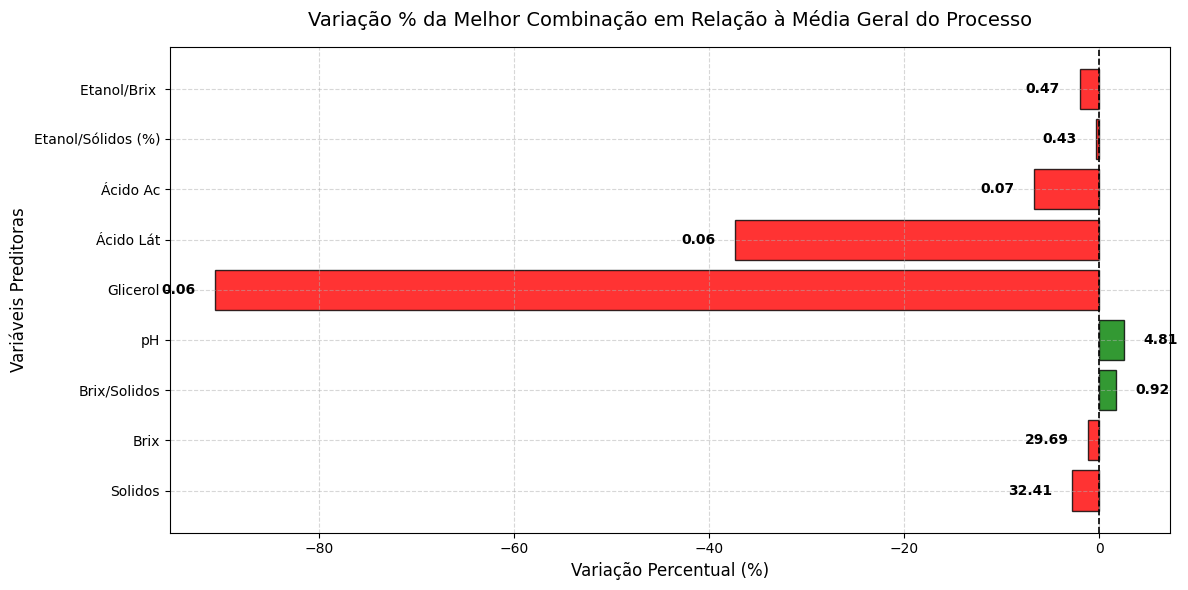

In [ ]:
# 5. Encontrar a melhor combinação de variáveis para maximizar o Etanol GL
# Vamos realizar uma busca sobre o grid de amostras reais e arredores para encontrar a maior predição
todas_predicoes = mlp.predict(scaler_X.transform(X_nn))
melhor_indice = np.argmax(todas_predicoes)

melhor_predicao = todas_predicoes[melhor_indice]
melhores_features = X_nn.iloc[melhor_indice]

# Exibir a melhor combinação encontrada
print("\n--- Melhor Combinação de Variáveis para Maximizar o Etanol GL (Previsão da Rede Neural) ---")
print(f"Previsão Máxima de Etanol GL: {melhor_predicao:.4f} GL\n")

df_melhor = pd.DataFrame(melhores_features).rename(columns={melhor_indice: 'Valor Ideal'})
display(df_melhor)

# 6. Plotar a melhor combinação em comparação com as médias gerais dos dados reais
medias_gerais = X_nn.mean()

plt.figure(figsize=(12, 6))
# Criando barras comparativas normalizadas para fins de visualização na mesma escala
# Normalizando para mostrar a variação percentual em relação à média geral
variacao_percentual = ((melhores_features - medias_gerais) / medias_gerais) * 100

cores_plot = ['green' if val >= 0 else 'red' for val in variacao_percentual]

plt.barh(variacao_percentual.index, variacao_percentual.values, color=cores_plot, edgecolor='black', alpha=0.8)
plt.axvline(0, color='black', linestyle='--', linewidth=1.2)

plt.title('Variação % da Melhor Combinação em Relação à Média Geral do Processo', fontsize=14, pad=15)
plt.xlabel('Variação Percentual (%)', fontsize=12)
plt.ylabel('Variáveis Preditoras', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)

# Adicionando os valores absolutos ideais nas pontas das barras para clareza
for index, value in enumerate(variacao_percentual.values):
    valor_real = melhores_features.values[index]
    alinhamento = 'left' if value >= 0 else 'right'
    deslocamento = 2 if value >= 0 else -2
    plt.text(value + deslocamento, index, f"{valor_real:.2f}", va='center', ha=alinhamento, fontweight='bold', fontsize=10)

plt.tight_layout()
plt.show()

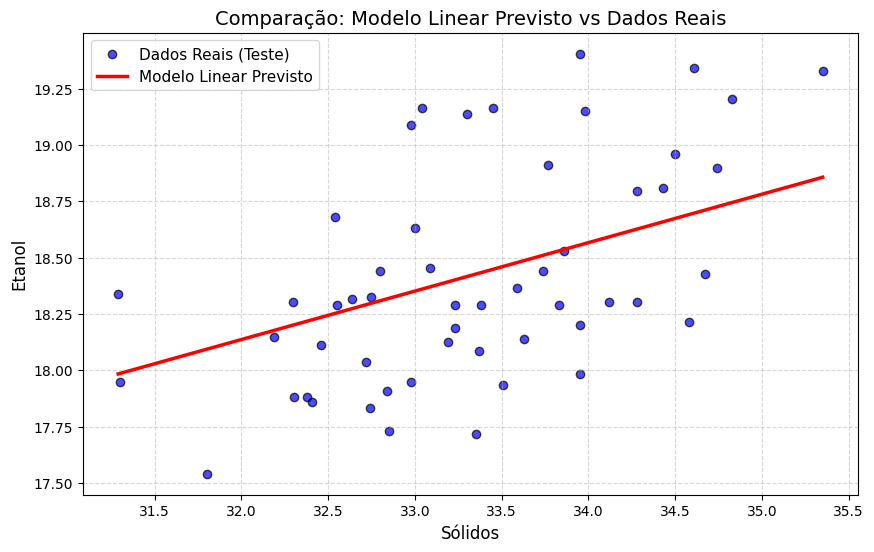

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Criando a figura para o gráfico
plt.figure(figsize=(10, 6))

# Plotando os dados reais de teste
plt.scatter(X_teste, Y_teste, color='blue', label='Dados Reais (Teste)', alpha=0.7, edgecolors='k')

# Plotando a reta prevista pelo modelo
# Extraímos a coluna como array do NumPy para usar o argsort e ordenar corretamente
valores_x = X_teste['Solidos'].values
ordenar_indices = np.argsort(valores_x)
X_teste_ordenado = valores_x[ordenar_indices]
Y_previsto_ordenado = Y_previsto[ordenar_indices]

plt.plot(X_teste_ordenado, Y_previsto_ordenado, color='red', linewidth=2.5, label='Modelo Linear Previsto')

# Customizações do gráfico
plt.title('Comparação: Modelo Linear Previsto vs Dados Reais', fontsize=14)
plt.xlabel('Sólidos', fontsize=12)
plt.ylabel('Etanol', fontsize=12)
plt.legend(fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)

# Exibindo o gráfico
plt.show()